# Proyecto Fase I — Sistema inteligente para clasificación y priorización de solicitudes

**Propósito académico.** Construir una base reproducible y escalable para las Fases I, II y III.

## Alcance
- Fase I: diagnóstico, análisis exploratorio, baseline de clasificación, insumos para business case y ROI.
- Fase II: comparación/optimización de modelos, análisis de errores, explicabilidad y validación.
- Fase III: arquitectura de despliegue, monitoreo, drift, gobernanza y human-in-the-loop.

> **Trazabilidad:** los datos del dataset se mantienen separados de los supuestos financieros simulados.


In [1]:
# Si se ejecuta en un entorno nuevo:
# !pip install -q kagglehub pandas numpy scikit-learn matplotlib openpyxl

import os, glob, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)


## 1. Descarga y selección del dataset

Se usa como fuente principal **Customer IT Support - Ticket Dataset** de Kaggle. El dataset es sintético y contiene, entre otros campos, texto del ticket, cola/departamento, prioridad, idioma, tipo y respuesta del agente.

La celda siguiente intenta descargarlo con `kagglehub`. Si el identificador cambia, basta con modificar `DATASET_HANDLE`; el resto del notebook detecta automáticamente los CSV disponibles.


In [2]:
import kagglehub

DATASET_HANDLE = "tobiasbueck/multilingual-customer-support-tickets"
try:
    path = kagglehub.dataset_download(DATASET_HANDLE)
    print("Dataset descargado en:", path)
except Exception as e:
    print("No fue posible descargar con el handle configurado.")
    print("Detalle:", e)
    print("Alternativa: descarga manualmente el CSV desde Kaggle y colócalo en ./data/")
    path = "./data"

files = []
for ext in ("*.csv","*.xlsx","*.json"):
    files.extend(glob.glob(os.path.join(path, "**", ext), recursive=True))
print("Archivos detectados:", files[:20])


100%|██████████| 16.1M/16.1M [00:00<00:00, 51.3MB/s]

Extracting files...


Dataset descargado en: /root/.cache/kagglehub/datasets/tobiasbueck/multilingual-customer-support-tickets/versions/14
Archivos detectados: ['/root/.cache/kagglehub/datasets/tobiasbueck/multilingual-customer-support-tickets/versions/14/dataset-tickets-multi-lang-4-20k.csv', '/root/.cache/kagglehub/datasets/tobiasbueck/multilingual-customer-support-tickets/versions/14/dataset-tickets-german_normalized.csv', '/root/.cache/kagglehub/datasets/tobiasbueck/multilingual-customer-support-tickets/versions/14/dataset-tickets-multi-lang3-4k.csv', '/root/.cache/kagglehub/datasets/tobiasbueck/multilingual-customer-support-tickets/versions/14/dataset-tickets-german_normalized_50_5_2.csv', '/root/.cache/kagglehub/datasets/tobiasbueck/multilingual-customer-support-tickets/versions/14/aa_dataset-tickets-multi-lang-5-2-50-version.csv']


In [3]:
def load_first_supported(files):
    if not files:
        raise FileNotFoundError("No se detectaron archivos de datos.")
    f = files[0]
    if f.lower().endswith(".csv"):
        return pd.read_csv(f)
    if f.lower().endswith(".xlsx"):
        return pd.read_excel(f)
    if f.lower().endswith(".json"):
        return pd.read_json(f)
    raise ValueError(f"Formato no soportado: {f}")

df = load_first_supported(files)
print("Dimensiones:", df.shape)
display(df.head())
print("\nColumnas:")
print(df.columns.tolist())


Dimensiones: (20000, 15)


,subject,body,answer,type,queue,priority,language,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Unvorhergesehener Absturz der Datenanalyse-Pla...,Die Datenanalyse-Plattform brach unerwartet ab...,Ich werde Ihnen bei der Lösung des Problems he...,Incident,General Inquiry,low,de,Crash,Technical,Bug,Hardware,Resolution,Outage,Documentation,NaN
1,Customer Support Inquiry,Seeking information on digital strategies that...,We offer a variety of digital strategies and s...,Request,Customer Service,medium,en,Feedback,Sales,IT,Tech Support,NaN,NaN,NaN,NaN
2,Data Analytics for Investment,I am contacting you to request information on ...,I am here to assist you with data analytics to...,Request,Customer Service,medium,en,Technical,Product,Guidance,Documentation,Performance,Feature,NaN,NaN
3,Krankenhaus-Dienstleistung-Problem,Ein Medien-Daten-Sperrverhalten trat aufgrund ...,Zurück zur E-Mail-Beschwerde über den Sperrver...,Incident,Customer Service,high,de,Security,Breach,Login,Maintenance,Incident,Resolution,Feedback,NaN
4,Security,"Dear Customer Support, I am reaching out to in...","Dear [name], we take the security of medical d...",Request,Customer Service,medium,en,Security,Customer,Compliance,Breach,Documentation,Guidance,NaN,NaN



Columnas:
['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']


## 2. Auditoría de calidad

Antes de modelar se revisan duplicados, valores faltantes, tipos de datos y cardinalidad. Esta auditoría evita presentar resultados sin conocer las limitaciones del conjunto.


In [4]:
audit = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean()*100).round(2),
    "unicos": df.nunique(dropna=False)
}).sort_values("pct_nulos", ascending=False)

print("Duplicados exactos:", df.duplicated().sum())
display(audit)


Duplicados exactos: 0


,tipo,nulos,pct_nulos,unicos
tag_8,object,18093,90.46,387
tag_7,object,16072,80.36,493
tag_6,object,12649,63.24,567
tag_5,object,6909,34.54,579
tag_4,object,1539,7.70,482
subject,object,1461,7.31,18540
tag_3,object,95,0.48,345
tag_2,object,46,0.23,205
answer,object,4,0.02,19997
body,object,2,0.01,19999


In [5]:
# Normalización de nombres para hacer el notebook tolerante a pequeñas variaciones.
norm = {c.lower().strip().replace(" ","_"): c for c in df.columns}

def pick_col(candidates):
    for c in candidates:
        if c in norm:
            return norm[c]
    return None

subject_col = pick_col(["subject","ticket_subject"])
body_col = pick_col(["body","ticket_description","description","text"])
queue_col = pick_col(["queue","department","ticket_type"])
priority_col = pick_col(["priority","ticket_priority"])
language_col = pick_col(["language","lang"])

print({
    "subject": subject_col,
    "body": body_col,
    "queue/target": queue_col,
    "priority": priority_col,
    "language": language_col
})


{'subject': 'subject', 'body': 'body', 'queue/target': 'queue', 'priority': 'priority', 'language': 'language'}


## 3. Construcción del texto y selección de objetivos

El primer objetivo técnico será **clasificar la cola/departamento**. La prioridad se conserva como segundo objetivo para escalar el proyecto posteriormente.

No se utilizarán campos posteriores a la atención (por ejemplo, una respuesta del agente) como predictores del enrutamiento inicial, ya que podrían introducir fuga de información.


In [6]:
if body_col is None:
    raise ValueError("No se encontró una columna de texto compatible.")
if queue_col is None:
    raise ValueError("No se encontró una columna objetivo de cola/departamento.")

subject = df[subject_col].fillna("").astype(str) if subject_col else ""
body = df[body_col].fillna("").astype(str)

if subject_col:
    df_model = df.assign(text=(subject + " " + body).str.strip())
else:
    df_model = df.assign(text=body.str.strip())

df_model = df_model[df_model["text"].str.len() > 0].copy()
df_model = df_model.dropna(subset=[queue_col])
print("Registros utilizables:", len(df_model))
display(df_model[[queue_col, "text"]].head())


Registros utilizables: 20000


,queue,text
0,General Inquiry,Unvorhergesehener Absturz der Datenanalyse-Pla...
1,Customer Service,Customer Support Inquiry Seeking information o...
2,Customer Service,Data Analytics for Investment I am contacting ...
3,Customer Service,Krankenhaus-Dienstleistung-Problem Ein Medien-...
4,Customer Service,"Security Dear Customer Support, I am reaching ..."


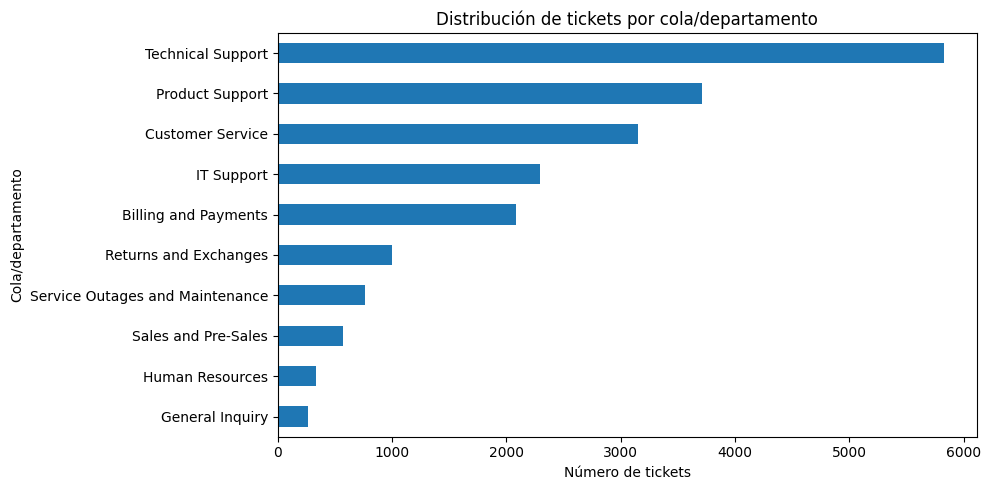

,tickets
priority,
medium,8144
high,7801
low,4055


,tickets
language,
en,11923
de,8077


In [7]:
# Distribuciones principales
fig, ax = plt.subplots(figsize=(10,5))
df_model[queue_col].value_counts().head(15).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Distribución de tickets por cola/departamento")
ax.set_xlabel("Número de tickets")
ax.set_ylabel("Cola/departamento")
plt.tight_layout()
plt.show()

if priority_col:
    display(df_model[priority_col].value_counts(dropna=False).rename("tickets").to_frame())
if language_col:
    display(df_model[language_col].value_counts(dropna=False).rename("tickets").to_frame())


## 4. Baseline reproducible: TF-IDF + Regresión Logística

Este modelo sirve como línea base. En Fase II podrá compararse con otros algoritmos o modelos de lenguaje. Se utiliza partición estratificada cuando la distribución de clases lo permite.


In [8]:
X = df_model["text"]
y = df_model[queue_col].astype(str)

counts = y.value_counts()
valid_classes = counts[counts >= 2].index
mask = y.isin(valid_classes)
X, y = X[mask], y[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1,2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

acc = accuracy_score(y_test, pred)
p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
    y_test, pred, average="macro", zero_division=0
)
p_weight, r_weight, f1_weight, _ = precision_recall_fscore_support(
    y_test, pred, average="weighted", zero_division=0
)

metrics = pd.DataFrame({
    "metrica":["Accuracy","Precision macro","Recall macro","F1 macro","F1 weighted"],
    "valor":[acc,p_macro,r_macro,f1_macro,f1_weight]
})
display(metrics)
print(classification_report(y_test, pred, zero_division=0))


,metrica,valor
0,Accuracy,0.416000
1,Precision macro,0.371725
2,Recall macro,0.439673
3,F1 macro,0.393346
4,F1 weighted,0.417572


                                 precision    recall  f1-score   support

           Billing and Payments       0.67      0.75      0.71       417
               Customer Service       0.38      0.37      0.37       630
                General Inquiry       0.21      0.36      0.26        53
                Human Resources       0.40      0.49      0.44        68
                     IT Support       0.33      0.36      0.35       458
                Product Support       0.41      0.28      0.34       742
          Returns and Exchanges       0.24      0.35      0.28       200
            Sales and Pre-Sales       0.20      0.45      0.28       114
Service Outages and Maintenance       0.37      0.58      0.45       153
              Technical Support       0.51      0.41      0.46      1165

                       accuracy                           0.42      4000
                      macro avg       0.37      0.44      0.39      4000
                   weighted avg       0.43      0

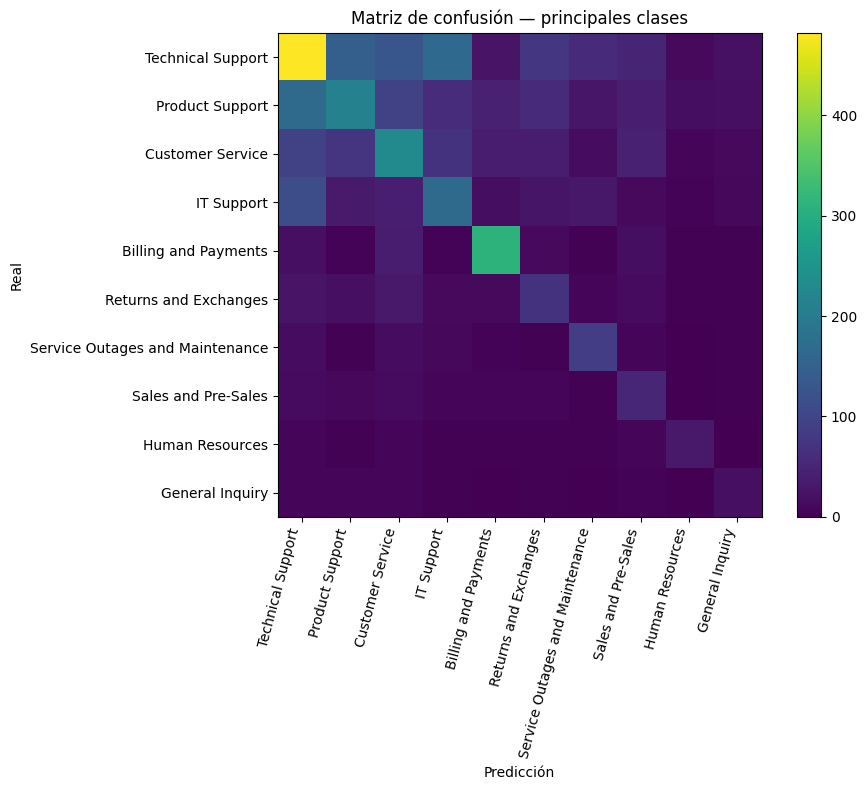

In [9]:
# Matriz de confusión para las clases más frecuentes
top_classes = y_test.value_counts().head(10).index.tolist()
mask_top = y_test.isin(top_classes)
cm = confusion_matrix(y_test[mask_top], pred[mask_top], labels=top_classes)

fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(cm)
ax.set_xticks(range(len(top_classes)))
ax.set_yticks(range(len(top_classes)))
ax.set_xticklabels(top_classes, rotation=75, ha="right")
ax.set_yticklabels(top_classes)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión — principales clases")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


## 5. Análisis de confianza y human-in-the-loop

Para escalar el proyecto no se propone automatización ciega. Los casos con confianza baja se derivarán a revisión humana. Esto permite estimar posteriormente una **tasa de automatización potencial** sin confundirla con exactitud.


In [10]:
if hasattr(pipeline.named_steps["clf"], "predict_proba"):
    proba = pipeline.predict_proba(X_test)
    confidence = proba.max(axis=1)
    eval_df = pd.DataFrame({
        "texto": X_test.values,
        "real": y_test.values,
        "prediccion": pred,
        "confianza": confidence
    })
    thresholds = []
    for t in [0.50,0.60,0.70,0.80,0.90]:
        accepted = eval_df["confianza"] >= t
        coverage = accepted.mean()
        selective_acc = (eval_df.loc[accepted,"real"] == eval_df.loc[accepted,"prediccion"]).mean() if accepted.any() else np.nan
        thresholds.append([t, coverage, selective_acc, accepted.sum()])
    threshold_df = pd.DataFrame(thresholds, columns=["umbral","cobertura_automatizable","accuracy_en_aceptados","tickets_aceptados"])
    display(threshold_df)
else:
    threshold_df = pd.DataFrame()


,umbral,cobertura_automatizable,accuracy_en_aceptados,tickets_aceptados
0,0.5,0.07100,0.940141,284
1,0.6,0.05375,0.986047,215
2,0.7,0.04300,0.982558,172
3,0.8,0.03025,0.991736,121
4,0.9,0.01475,1.000000,59


## 6. Segundo frente de escalamiento: prioridad

En Fase I sólo se audita la disponibilidad y distribución de la prioridad. En Fase II puede entrenarse un segundo clasificador y analizar si la predicción de prioridad es suficientemente confiable para apoyar —no sustituir— la decisión operativa.


In [11]:
if priority_col:
    priority_analysis = (
        df_model[priority_col]
        .value_counts(dropna=False)
        .rename_axis("prioridad")
        .reset_index(name="tickets")
    )
    priority_analysis["porcentaje"] = (priority_analysis["tickets"]/priority_analysis["tickets"].sum()*100).round(2)
    display(priority_analysis)
else:
    priority_analysis = pd.DataFrame()
    print("El dataset cargado no expone una columna de prioridad reconocida.")


,prioridad,tickets,porcentaje
0,medium,8144,40.72
1,high,7801,39.01
2,low,4055,20.28


## 7. Exportación de evidencia para Excel y el Business Case

Los resultados se exportan sin inventar métricas. El Excel financiero utilizará estos archivos para sustituir los supuestos preliminares por resultados observados cuando corresponda.


In [12]:
RESULTS_DIR = Path("resultados_fase1")
RESULTS_DIR.mkdir(exist_ok=True)

audit.reset_index(names="variable").to_csv(RESULTS_DIR/"auditoria_dataset.csv", index=False)
metrics.to_csv(RESULTS_DIR/"metricas_baseline.csv", index=False)

dist_queue = df_model[queue_col].value_counts().rename_axis("cola").reset_index(name="tickets")
dist_queue.to_csv(RESULTS_DIR/"distribucion_colas.csv", index=False)

if not threshold_df.empty:
    threshold_df.to_csv(RESULTS_DIR/"analisis_umbrales.csv", index=False)
if not priority_analysis.empty:
    priority_analysis.to_csv(RESULTS_DIR/"distribucion_prioridad.csv", index=False)

summary = {
    "registros_dataset": int(len(df)),
    "registros_modelo": int(len(df_model)),
    "target": queue_col,
    "accuracy": float(acc),
    "f1_macro": float(f1_macro),
    "f1_weighted": float(f1_weight)
}
with open(RESULTS_DIR/"resumen_modelo.json","w",encoding="utf-8") as f:
    json.dump(summary,f,ensure_ascii=False,indent=2)

print("Archivos exportados en:", RESULTS_DIR.resolve())
print(json.dumps(summary, ensure_ascii=False, indent=2))


Archivos exportados en: /content/resultados_fase1
{
  "registros_dataset": 20000,
  "registros_modelo": 20000,
  "target": "queue",
  "accuracy": 0.416,
  "f1_macro": 0.3933463536709715,
  "f1_weighted": 0.41757183354780864
}


## 8. Puente hacia Fases II y III

### Fase II
1. Comparar varios modelos.
2. Optimizar hiperparámetros.
3. Analizar errores por clase e idioma.
4. Evaluar prioridad como segundo objetivo.
5. Incorporar explicabilidad y revisión de sesgo.
6. Definir umbral de confianza para human-in-the-loop.

### Fase III
1. Empaquetar el modelo.
2. Diseñar API y arquitectura.
3. Definir monitoreo de calidad y drift.
4. Registrar decisiones y trazabilidad.
5. Establecer controles de privacidad y seguridad.
6. Diseñar piloto, rollback y KPIs productivos.

**Regla del proyecto:** ninguna métrica técnica o financiera se presentará como real hasta haber sido obtenida o identificada explícitamente como supuesto académico.
